In [2]:
# 1. Core library imports
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure professional plot aesthetics for academic reporting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

# 2. Load the processed Premier League dataset
data_path = os.path.join('..', 'data', 'processed', 'premier_league_2014_2024.csv')
df = pd.read_csv(data_path)

print(f"Dataset successfully loaded from: {data_path}")
print(f"Total Rows (Matches): {df.shape[0]}")
print(f"Total Columns (Features): {df.shape[1]}")
df[['MatchDate', 'HomeTeam', 'AwayTeam', 'HomeElo', 'AwayElo', 'FTResult', 'HomeWin']].head()

Dataset successfully loaded from: ../data/processed/premier_league_2014_2024.csv
Total Rows (Matches): 4178
Total Columns (Features): 50


,MatchDate,HomeTeam,AwayTeam,HomeElo,AwayElo,FTResult,HomeWin
0,2014-01-01,Arsenal,Cardiff,1897.62,1591.51,H,1
1,2014-01-01,Crystal Palace,Norwich,1546.53,1652.06,D,0
2,2014-01-01,Fulham,West Ham,1625.78,1648.36,H,1
3,2014-01-01,Liverpool,Hull,1835.75,1597.95,H,1
4,2014-01-01,Man United,Tottenham,1922.74,1825.01,A,0


### 1. Target Distribution & Baseline Analysis
Before exploring predictor features, we analyze the balance of the target variable `HomeWin`. In association football, home advantage is a well-documented empirical phenomenon. Understanding this distribution defines our majority-class baseline accuracy and confirms whether resampling techniques (e.g., SMOTE) are required.

/var/folders/bd/rzzq2vs13nncxn099bq37zdw0000gn/T/ipykernel_98710/121987186.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='HomeWin', palette=['#4C72B0', '#55A868'])


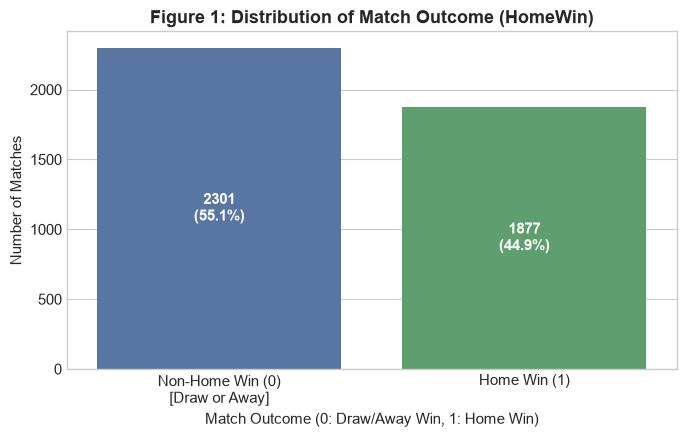

Class 0 (Non-Home Win): 2301 matches (55.07%)
Class 1 (Home Win): 1877 matches (44.93%)
Majority-class Baseline Accuracy: 55.07%


In [3]:
# 3. Figure 1: Target Variable Distribution (HomeWin)
plt.figure(figsize=(7, 4.5))

# Count plot with custom styling
ax = sns.countplot(data=df, x='HomeWin', palette=['#4C72B0', '#55A868'])

plt.title('Figure 1: Distribution of Match Outcome (HomeWin)', fontsize=13, weight='bold')
plt.xlabel('Match Outcome (0: Draw/Away Win, 1: Home Win)', fontsize=11)
plt.ylabel('Number of Matches', fontsize=11)
plt.xticks([0, 1], ['Non-Home Win (0)\n[Draw or Away]', 'Home Win (1)'])

# Add percentage and count labels on top of bars
total = len(df)
for p in ax.patches:
    height = p.get_height()
    percentage = f'{100 * height / total:.1f}%'
    ax.annotate(f'{int(height)}\n({percentage})',
                (p.get_x() + p.get_width() / 2., height / 2),
                ha='center', va='center', fontsize=11, color='white', weight='bold')

plt.tight_layout()
os.makedirs('../report/figures', exist_ok=True)
plt.savefig('../report/figures/fig1_target_distribution.png', dpi=300)
plt.show()

# Empirical summary printout
home_wins = df['HomeWin'].sum()
non_home = total - home_wins
print(f"Class 0 (Non-Home Win): {non_home} matches ({non_home/total*100:.2f}%)")
print(f"Class 1 (Home Win): {home_wins} matches ({home_wins/total*100:.2f}%)")
print(f"Majority-class Baseline Accuracy: {max(home_wins, non_home)/total*100:.2f}%")

### 2. Bivariate Analysis: Team Strength Discrepancy (EloDiff) vs Match Outcome
To assess whether historical team strength serves as a discriminative predictor for match outcomes, we compute the rating discrepancy: `EloDiff = HomeElo - AwayElo`. Using a boxplot, we evaluate the distribution of this differential across home victories (1) and non-home victories (0), identifying central tendencies, interquartile ranges, and potential outliers.

/var/folders/bd/rzzq2vs13nncxn099bq37zdw0000gn/T/ipykernel_98710/541292814.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='HomeWin', y='EloDiff', palette=['#4C72B0', '#55A868'], width=0.45)


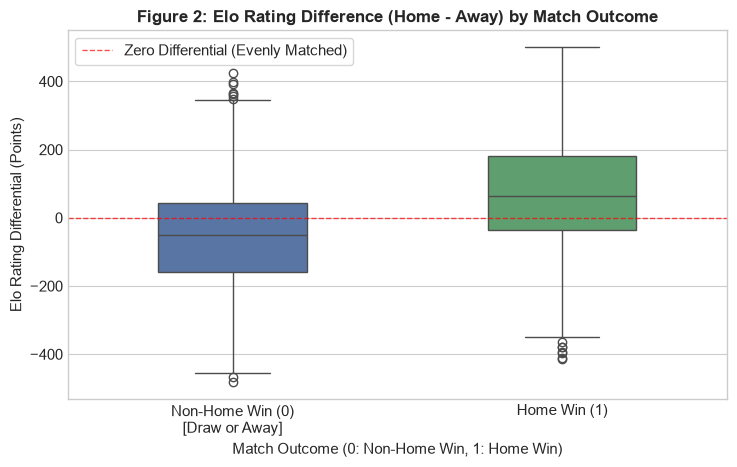

--- Elo Differential Summary Statistics ---
          count   mean     std     min     25%    50%     75%     max
HomeWin                                                              
0        2300.0 -55.68  151.19 -482.21 -159.87 -51.51   42.60  425.32
1        1876.0  68.11  154.44 -414.45  -36.75  62.72  180.57  500.15


In [4]:
# Feature engineering: calculate Elo rating discrepancy
df['EloDiff'] = df['HomeElo'] - df['AwayElo']

# Create Figure 2: Bivariate Boxplot
plt.figure(figsize=(7.5, 4.8))
sns.boxplot(data=df, x='HomeWin', y='EloDiff', palette=['#4C72B0', '#55A868'], width=0.45)

plt.title('Figure 2: Elo Rating Difference (Home - Away) by Match Outcome', fontsize=12, weight='bold')
plt.xlabel('Match Outcome (0: Non-Home Win, 1: Home Win)', fontsize=11)
plt.ylabel('Elo Rating Differential (Points)', fontsize=11)
plt.xticks([0, 1], ['Non-Home Win (0)\n[Draw or Away]', 'Home Win (1)'])
plt.axhline(0, color='red', linestyle='--', linewidth=1, alpha=0.7, label='Zero Differential (Evenly Matched)')
plt.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.savefig('../report/figures/fig2_elodiff_boxplot.png', dpi=300)
plt.show()

# Print summary statistics for both groups
print("--- Elo Differential Summary Statistics ---")
print(df.groupby('HomeWin')['EloDiff'].describe().round(2))

### 3. Multivariate Correlation Analysis: Pre-Match Features
To identify multicollinearity, evaluate linear dependencies, and prevent redundant feature inclusion, we compute Pearson's correlation matrix across pre-match metrics: Elo ratings, short/medium-term form points (Form3, Form5), and opening bookmaker odds. All post-match metrics remain strictly excluded to eliminate temporal data leakage.

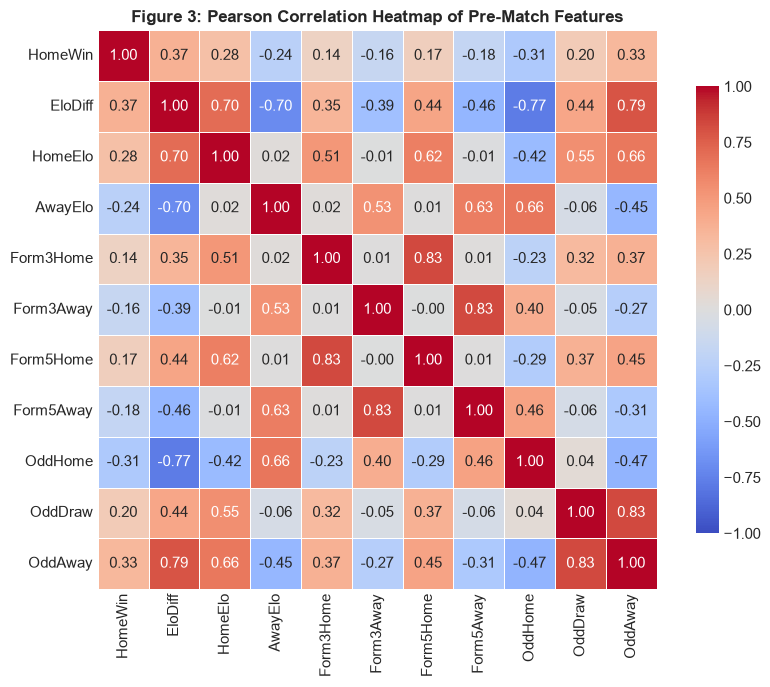

--- Linear Correlation with HomeWin (Target) ---
HomeWin      1.000
EloDiff      0.374
OddAway      0.333
HomeElo      0.281
OddDraw      0.201
Form5Home    0.171
Form3Home    0.136
Form3Away   -0.161
Form5Away   -0.176
AwayElo     -0.242
OddHome     -0.311
Name: HomeWin, dtype: float64


In [5]:
# 4. Figure 3: Correlation Heatmap of Pre-Match Numerical Features
selected_features = [
    'HomeWin', 'EloDiff', 'HomeElo', 'AwayElo',
    'Form3Home', 'Form3Away', 'Form5Home', 'Form5Away',
    'OddHome', 'OddDraw', 'OddAway'
]

corr_matrix = df[selected_features].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})

plt.title('Figure 3: Pearson Correlation Heatmap of Pre-Match Features', fontsize=12, weight='bold')
plt.tight_layout()
plt.savefig('../report/figures/fig3_correlation_heatmap.png', dpi=300)
plt.show()

# Print ranked correlations with HomeWin
print("--- Linear Correlation with HomeWin (Target) ---")
print(corr_matrix['HomeWin'].sort_values(ascending=False).round(3))